In [1]:
import pandas as pd
import numpy as np

In [2]:
#the output of 00_data_understanding_cleaning.ipynb, same row order in both files
df = pd.read_parquet('Data/Processed.parquet')
emb = np.load('Data/caption_emb_512.npy')
print(df.shape, emb.shape)

(500000, 34) (500000, 512)


In [3]:
# split by column name instead of position, positions break as soon as we add a feature
df_y = df[['is_ai_generated']]
df_x = df.drop(columns=['is_ai_generated'])

In [4]:
# counts like views / likes / durations go from 0 to millions
# without log a few viral posts dominate the scaling and everything else is squashed near 0
log_cols = ['duration_ms', 'image_count', 'width', 'height', 'views', 'likes', 'comments', 'shares', 'saves', 'downloads',
            'engagement_rate', 'n_hashtags', 'update_delay_min', 'on_screen_text_length', 'cap_len', 'cap_emoji']

df_x[log_cols] = np.log1p(df_x[log_cols].astype('float32').clip(lower=0))

In [5]:
labels = list(df_y.columns)

In [6]:
# caption embeddings go next to the tabular features as emb_ columns
emb_cols = [f'emb_{i}' for i in range(emb.shape[1])]
df_x_t = pd.concat([df_x, pd.DataFrame(emb, columns=emb_cols, index=df_x.index)], axis=1)

In [7]:
#transforming the data into tensors

import torch
df_x_t = df_x_t.astype('float32')
X_t = torch.from_numpy(df_x_t.to_numpy().copy())
print(X_t.shape, X_t.dtype)   # torch.Size([500k, 545]) torch.float32
df_y_t = df_y.astype('float32')
Y_t = torch.from_numpy(df_y_t.to_numpy().copy())
print(Y_t.shape, Y_t.dtype)

torch.Size([500000, 545]) torch.float32
torch.Size([500000, 1]) torch.float32


In [8]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import TensorDataset, DataLoader
import torchmetrics
from torchmetrics.aggregation import MeanMetric
from copy import deepcopy

os.makedirs('models', exist_ok=True)
os.makedirs('labels', exist_ok=True)

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
std = StandardScaler()

In [10]:
# about 22% of captions show up more than once (reposts, templates)
# with a normal random split the same caption lands in train and test and the model just remembers it
# the cleaning dropped the caption, but the same caption always has the exact same embedding,
# so we group posts by their embedding and keep each group on one side
groups = pd.factorize(pd.util.hash_pandas_object(pd.DataFrame(emb), index=False))[0]
no_caption = (emb == 0).all(axis=1)
groups[no_caption] = groups.max() + 1 + np.arange(no_caption.sum())  # posts without caption are each their own group

idx = np.arange(len(df))
split1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, rest_idx = next(split1.split(idx, groups=groups))
split2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_part, test_part = next(split2.split(rest_idx, groups=groups[rest_idx]))
val_idx, test_idx = rest_idx[val_part], rest_idx[test_part]

X_train, X_val, X_test = X_t[train_idx], X_t[val_idx], X_t[test_idx]
Y_train, Y_val, Y_test = Y_t[train_idx], Y_t[val_idx], Y_t[test_idx]
print(X_train.shape, X_val.shape, X_test.shape)
print('captions in both train and test:', len(set(groups[train_idx]) & set(groups[test_idx])))

torch.Size([402330, 545]) torch.Size([49387, 545]) torch.Size([48283, 545])
captions in both train and test: 0


In [11]:
X_train, X_test, X_val = std.fit_transform(X_train), std.transform(X_test), std.transform(X_val)

# an app would need the exact same scaling
joblib.dump(std, 'models/scaler.pkl')

['models/scaler.pkl']

In [12]:
#MODEL CLASS

class AIDetectorMLP(nn.Module):
    def __init__(self,in_dim,out_dim,hidden = 1024,p=0.5):
        super().__init__()
        def block(ins,outs):
            return nn.Sequential(
                nn.Linear(ins,outs),
                nn.ReLU(),
                nn.Dropout(p),


            )
        self.net = nn.Sequential(block(in_dim,hidden),block(hidden,hidden//2),block(hidden//2,hidden//4),nn.Linear(hidden//4, out_dim))

    def forward(self,x):
        return self.net(x)

In [13]:
#loss function
loss_fn = nn.BCEWithLogitsLoss()

In [14]:
#dtype correction
X_train = torch.from_numpy(X_train).float()
X_val   = torch.from_numpy(X_val).float()
X_test  = torch.from_numpy(X_test).float()

In [15]:
def train_model(X_train, Y_train, X_val, Y_val, name, epochs=200, patience=15):

    # CONFIG
    train_losses = []
    val_losses = []
    AP = []  # average precision on val
    best_model_path = f"models/best_{name}.pth"
    tune_model = False
    save_model = False


    # CHECKPOINTS
    model = AIDetectorMLP(X_train.shape[1], Y_train.shape[1]).to(device)
    if tune_model is True:
        try:
            model.load_state_dict(torch.load(best_model_path, map_location=device))
        except FileNotFoundError:
            print('No best model was found starting from zero')


    # OPTIMIZER
    optim = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-2,
    )


    # METRICS
    train_loss_metric = torchmetrics.aggregation.MeanMetric().to(device)
    val_AP_metric = torchmetrics.classification.BinaryAveragePrecision().to(device)
    val_loss_metric = torchmetrics.aggregation.MeanMetric().to(device)

    best_metric = -1.0
    best_epoch = -1


    # DATALOADERS
    train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=2048, shuffle=True)
    val_loader   = DataLoader(TensorDataset(X_val, Y_val),     batch_size=4096, shuffle=False)


    # TRAINING LOOP
    for epoch in range(epochs):

        model.train()
        train_loss_metric.reset()

        for xb, yb in train_loader:

            xb, yb = xb.to(device), yb.to(device)
            optim.zero_grad()

            loss = loss_fn(model(xb), yb)
            train_loss_metric.update(loss.item(), weight=xb.size(0))

            loss.backward()
            optim.step()

        train_losses.append(train_loss_metric.compute().item())

        model.eval()
        val_AP_metric.reset()
        val_loss_metric.reset()

        with torch.inference_mode():

            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                val_loss_metric.update(loss_fn(logits, yb).item(), weight=xb.size(0))
                val_AP_metric.update(logits.squeeze(1), yb.squeeze(1).int())

            AP.append(val_AP_metric.compute().item())
            val_losses.append(val_loss_metric.compute().item())

            if AP[-1] > best_metric:
                best_metric = AP[-1]
                best_epoch = epoch
                torch.save(deepcopy(model.state_dict()), best_model_path)

        # early stopping, after a few epochs it only overfits
        if epoch - best_epoch >= patience:
            print(f'[{name}] no improvement for {patience} epochs, stopping at epoch {epoch}')
            break

        if epoch % 10 == 0:
            print(f'[{name}] Training loss = {train_losses[-1]} validation loss is {val_losses[-1]}, AP = {AP[-1]}')
            if best_epoch >= 0:
                print(f'[{name}] best so far: AP = {best_metric:.4f} epoch {best_epoch} -> {best_model_path}')

    return model, AP, best_metric, best_model_path, val_losses

In [16]:
#finding out what are the indices for making 2 seperate models
tab_idx = [df_x_t.columns.get_loc(c) for c in df_x_t.columns if not c.startswith('emb_')]
all_idx = list(range(df_x_t.shape[1]))

# tabular features only
model_tab, AP_tab, best_tab, path_tab, val_losses_tab = train_model(
    X_train[:, tab_idx], Y_train,
    X_val[:, tab_idx],   Y_val,
    name='tabular'
)

# tabular + caption embeddings
model_full, AP_full, best_full, path_full, val_losses_full = train_model(
    X_train[:, all_idx], Y_train,
    X_val[:, all_idx],   Y_val,
    name='full'
)

[tabular] Training loss = 0.5697959065437317 validation loss is 0.5407313704490662, AP = 0.8005691170692444
[tabular] best so far: AP = 0.8006 epoch 0 -> models/best_tabular.pth


[tabular] Training loss = 0.517631471157074 validation loss is 0.512001097202301, AP = 0.8262104392051697
[tabular] best so far: AP = 0.8262 epoch 10 -> models/best_tabular.pth


[tabular] Training loss = 0.5073397755622864 validation loss is 0.5069645047187805, AP = 0.8306014537811279
[tabular] best so far: AP = 0.8310 epoch 19 -> models/best_tabular.pth


[tabular] Training loss = 0.5007690191268921 validation loss is 0.5013152360916138, AP = 0.834400475025177
[tabular] best so far: AP = 0.8344 epoch 30 -> models/best_tabular.pth


[tabular] Training loss = 0.4963313937187195 validation loss is 0.49949806928634644, AP = 0.835873007774353
[tabular] best so far: AP = 0.8359 epoch 40 -> models/best_tabular.pth


...

[tabular] no improvement for 15 epochs, stopping at epoch 89


[full] Training loss = 0.5599331855773926 validation loss is 0.5304258465766907, AP = 0.8125715255737305
[full] best so far: AP = 0.8126 epoch 0 -> models/best_full.pth


[full] Training loss = 0.470355749130249 validation loss is 0.5006859302520752, AP = 0.8384456634521484
[full] best so far: AP = 0.8394 epoch 9 -> models/best_full.pth


[full] Training loss = 0.4378660321235657 validation loss is 0.5011622905731201, AP = 0.838947057723999
[full] best so far: AP = 0.8410 epoch 14 -> models/best_full.pth


[full] no improvement for 15 epochs, stopping at epoch 29


In [17]:
#data sanity check
print(f'ai rate train: {Y_train.mean():.3f}')
print(f'ai rate val:   {Y_val.mean():.3f}')
print(f'ai rate test:  {Y_test.mean():.3f}')

ai rate train: 0.501
ai rate val:   0.497
ai rate test:  0.496


In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

os.makedirs("plots", exist_ok=True)

# the models trained on 50/50 so their probabilities think ai is way more common than it is
# adding log(real odds) - log(train odds) to the logit gives probabilities for the real rate
real_rate = 0.0577   # real ai rate of tagged posts in september (from the natural test sample)
train_rate = Y_train.mean().item()
prior_shift = np.log(real_rate / (1 - real_rate)) - np.log(train_rate / (1 - train_rate))

# val and test are 50/50 too, these weights make them count like real data
# an ai post counts as 0.115 posts and a normal post as 1.885 posts
def real_weights(y):
    return np.where(y == 1, real_rate / train_rate, (1 - real_rate) / (1 - train_rate))


def eval_model(model, AP_hist, val_loss_hist, ckpt_path,
               X_val, Y_val, X_test, Y_test, tag):
    # load best weights
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()

    # curves
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(AP_hist)
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('AP')
    ax[0].set_title(f'{tag} val AP')
    ax[0].axhline(max(AP_hist), color='r', ls='--', alpha=0.5,
                  label=f'best {max(AP_hist):.3f}')
    ax[0].legend()

    ax[1].plot(val_loss_hist, color='orange')
    ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss')
    ax[1].set_title(f'{tag} val loss')
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_curves.png', dpi=120)
    plt.show()

    # preds, shifted to the real ai rate
    with torch.inference_mode():
        p_val = torch.sigmoid(model(X_val.to(device)) + prior_shift).cpu().numpy().ravel()
        p_test = torch.sigmoid(model(X_test.to(device)) + prior_shift).cpu().numpy().ravel()
    yv, yt = Y_val.numpy().ravel(), Y_test.numpy().ravel()
    wv, wt = real_weights(yv), real_weights(yt)


    # precision recall curve at the real rate
    prec, rec, _ = precision_recall_curve(yt, p_test, sample_weight=wt)
    plt.figure(figsize=(6, 5))
    plt.plot(rec, prec)
    plt.axhline(real_rate, color='gray', ls='--', label=f'random {real_rate:.3f}')
    plt.xlabel('recall'); plt.ylabel('precision')
    plt.title(f'{tag} precision recall (test, real ai rate)')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_pr_curve.png', dpi=120)
    plt.show()

    # preds ai vs not ai
    plt.figure(figsize=(8, 4))
    plt.hist(p_test[yt == 0], bins=50, alpha=0.6, density=True, label='not ai')
    plt.hist(p_test[yt == 1], bins=50, alpha=0.6, density=True, label='ai')
    plt.yscale('log')
    plt.xlabel('predicted probability'); plt.ylabel('density')
    plt.title(f'{tag} preds ai vs not ai (test)')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_pred_dist.png', dpi=120)
    plt.show()

    # precision and recall for every threshold
    ts = np.linspace(0.01, 0.95, 95)
    precs, recs = [], []
    for t in ts:
        f = p_test >= t
        precs.append((wt * yt)[f].sum() / wt[f].sum() if f.any() else np.nan)
        recs.append((wt * yt)[f].sum() / (wt * yt).sum())
    plt.figure(figsize=(8, 4))
    plt.plot(ts, precs, label='precision')
    plt.plot(ts, recs, label='recall')
    plt.xlabel('threshold'); plt.ylabel('value')
    plt.title(f'{tag} precision / recall vs threshold (test, real ai rate)')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_thresholds.png', dpi=120)
    plt.show()

    print(f'[{tag}] test AP (50/50)    : {average_precision_score(yt, p_test):.4f}')
    print(f'[{tag}] test ROC-AUC       : {roc_auc_score(yt, p_test):.4f}')
    print(f'[{tag}] test AP (real rate): {average_precision_score(yt, p_test, sample_weight=wt):.4f}')
    print(f'[{tag}] best val           : {max(AP_hist):.4f} (epoch {AP_hist.index(max(AP_hist))})')
    print()

    return p_val, p_test

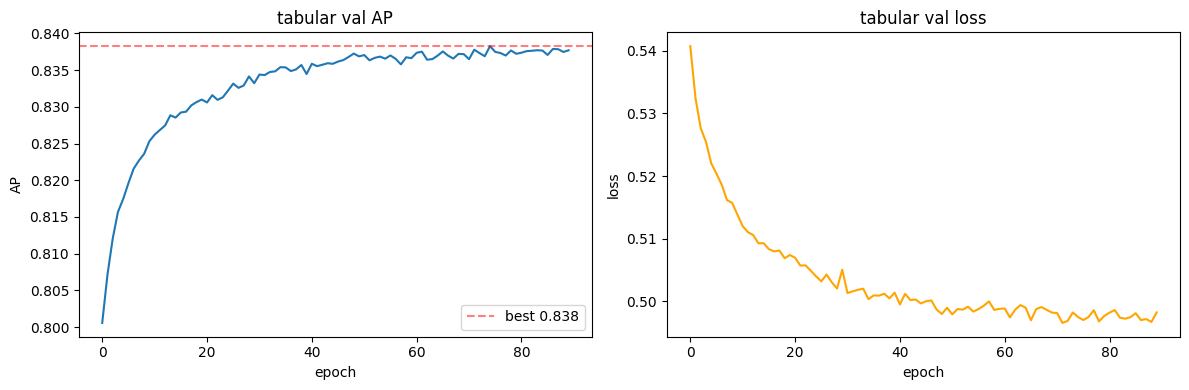

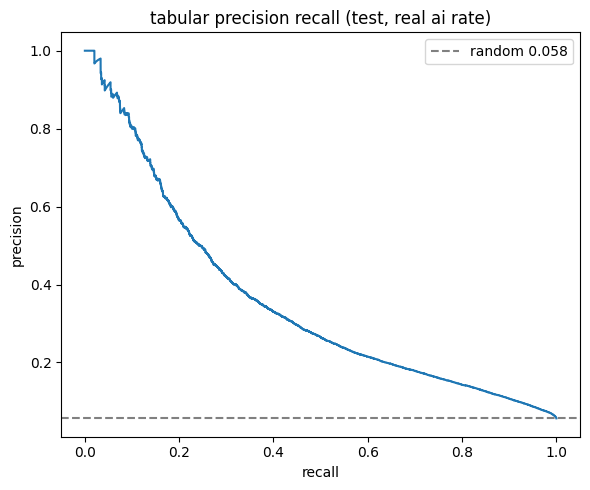

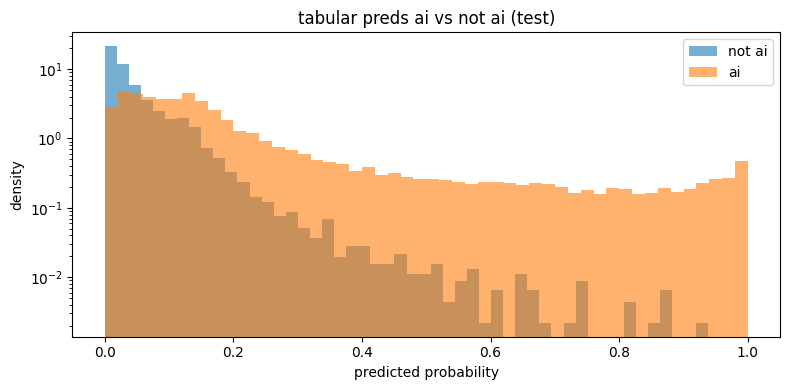

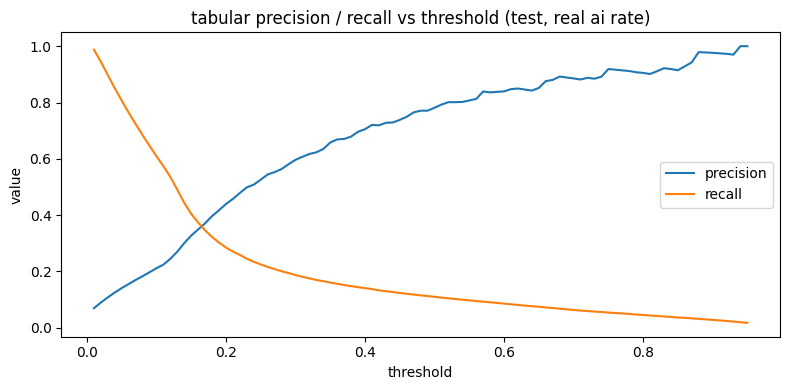

[tabular] test AP (50/50)    : 0.8381
[tabular] test ROC-AUC       : 0.8391
[tabular] test AP (real rate): 0.3560
[tabular] best val           : 0.8383 (epoch 74)



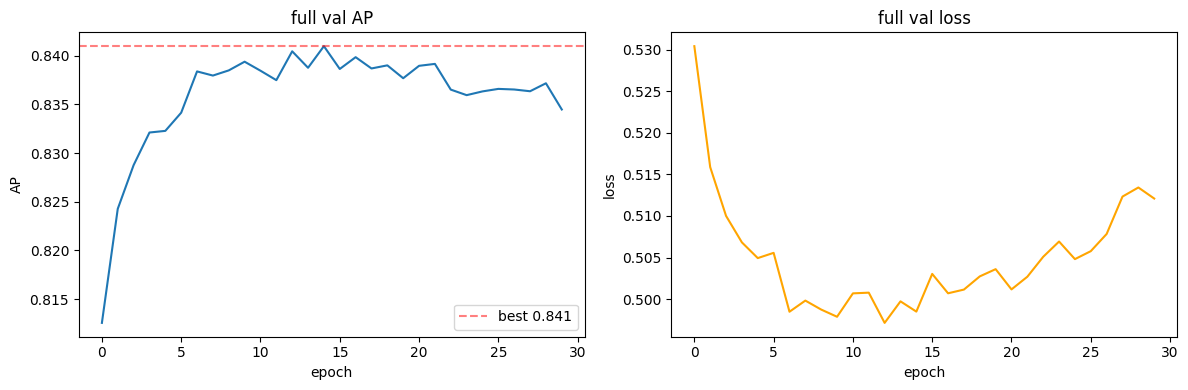

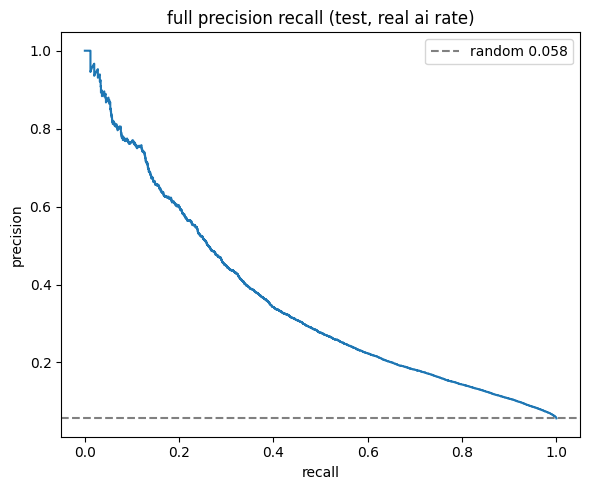

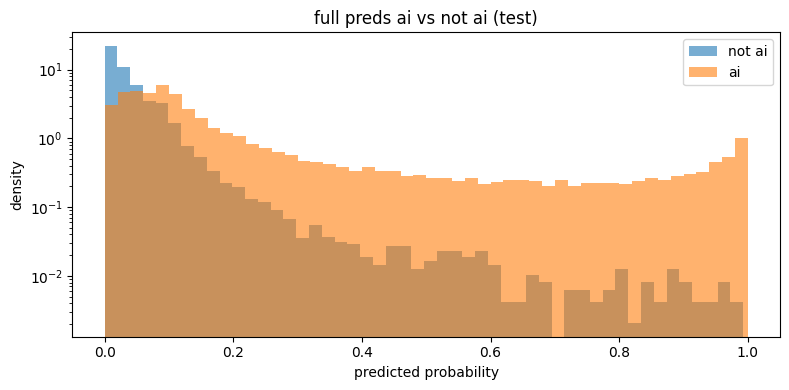

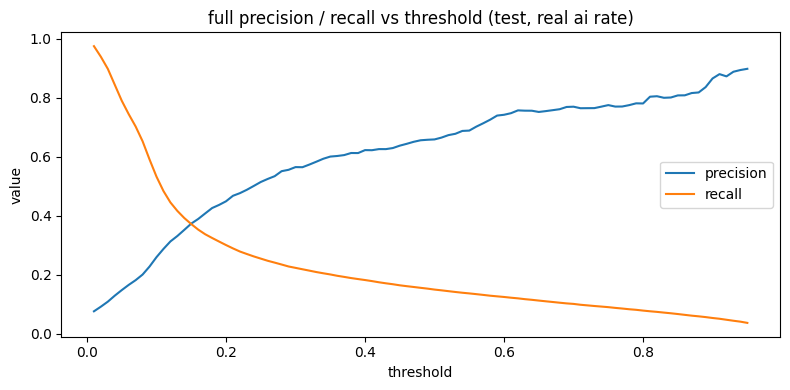

[full] test AP (50/50)    : 0.8411
[full] test ROC-AUC       : 0.8408
[full] test AP (real rate): 0.3590
[full] best val           : 0.8410 (epoch 14)



In [19]:
#evalutating the models
p_val_tab, p_test_tab = eval_model(model_tab, AP_tab, val_losses_tab, path_tab,
                                X_val[:, tab_idx], Y_val, X_test[:, tab_idx], Y_test, 'tabular')

p_val_full, p_test_full = eval_model(model_full, AP_full, val_losses_full, path_full,
                                  X_val, Y_val, X_test, Y_test, 'full')

In [20]:
df_x_t.columns

Index(['duration_ms', 'image_count', 'width', 'height', 'is_ad',
       'is_shop_video', 'not_recommended_for_fyp', 'sound_muted', 'views',
       'likes',
       ...
       'emb_502', 'emb_503', 'emb_504', 'emb_505', 'emb_506', 'emb_507',
       'emb_508', 'emb_509', 'emb_510', 'emb_511'],
      dtype='str', length=545)

In [21]:
#we should save the label and log columns for an app
labels_path = ('labels/')

pd.DataFrame([labels]).to_csv(labels_path + "labels_ai.csv", index=False)
pd.Series(log_cols).to_csv(labels_path + "log_columns.csv", index=False, header=False)

In [22]:
tabular_cols = [c for c in df_x_t.columns if not c.startswith("emb_")]
pd.Series(tabular_cols).to_csv("labels/feature_columns.csv", index=False, header=False)

In [23]:
tabular_cols

['duration_ms',
 'image_count',
 'width',
 'height',
 'is_ad',
 'is_shop_video',
 'not_recommended_for_fyp',
 'sound_muted',
 'views',
 'likes',
 'comments',
 'shares',
 'saves',
 'downloads',
 'engagement_rate',
 'cnt_duration',
 'cnt_res',
 'cnt_sound',
 'tag_cnt_mean',
 'dur_ms_part',
 'aspect',
 'cap_len',
 'cap_upper_ratio',
 'cap_emoji',
 'sound_age_log',
 'lang_freq',
 'country_freq',
 'is_branded',
 'n_hashtags',
 'has_mentions',
 'type_video',
 'update_delay_min',
 'on_screen_text_length']

In [24]:
#CHECKING THRESHOLDS
#we use the full model from here (tabular + captions)
y_test = Y_test.numpy().ravel()
w_test = real_weights(y_test)
p_val_best, p_test_best = p_val_full, p_test_full

#test is 50/50, so every post counts with its weight to look like real data
def precision_recall(p, y, w, t):
    flagged = p >= t
    caught = (w * y)[flagged].sum()
    wrong = (w * (1 - y))[flagged].sum()
    all_ai = (w * y).sum()
    if caught + wrong == 0:
        return 0, 0
    return caught / (caught + wrong), caught / all_ai

#first just look at what every threshold does on test
print('threshold | precision | recall | flagged')
for t in [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    precision, recall = precision_recall(p_test_best, y_test, w_test, t)
    flagged = w_test[p_test_best >= t].sum() / w_test.sum()
    print(f'{t:9} | {precision:9.3f} | {recall:6.3f} | {flagged:6.1%}')

threshold | precision | recall | flagged
     0.05 |     0.147 |  0.789 |  30.4%
      0.1 |     0.259 |  0.532 |  11.6%
     0.15 |     0.373 |  0.371 |   5.6%
      0.2 |     0.448 |  0.300 |   3.8%
     0.25 |     0.514 |  0.254 |   2.8%
      0.3 |     0.564 |  0.223 |   2.2%
      0.4 |     0.622 |  0.181 |   1.6%
      0.5 |     0.658 |  0.149 |   1.3%
      0.6 |     0.742 |  0.124 |   0.9%
      0.7 |     0.769 |  0.100 |   0.7%
      0.8 |     0.780 |  0.078 |   0.6%
      0.9 |     0.865 |  0.053 |   0.3%


In [25]:
#now pick the 2 cut offs for the human review idea
#posts above the high one get flagged as ai automatically
#posts between the high and the low one go to a person
#posts under the low one pass

#we pick them on val and NOT on test, otherwise we are cheating
y_val = Y_val.numpy().ravel()
w_val = real_weights(y_val)

#high cut off: try every threshold from 0.99 down and keep the lowest one where at least 85% of the flagged posts are ai
auto_thr = 0.99
t = 0.99
while t > 0.01:
    precision, recall = precision_recall(p_val_best, y_val, w_val, t)
    if precision >= 0.85:
        auto_thr = t
    t = round(t - 0.01, 2)
print('auto flag threshold:', auto_thr)

#low cut off: go down from the high one until we catch 70% of all ai
review_thr = auto_thr
t = auto_thr
while t > 0.001:
    precision, recall = precision_recall(p_val_best, y_val, w_val, t)
    if recall >= 0.70:
        review_thr = t
        break
    t = round(t - 0.001, 3)
print('review threshold:', review_thr)

auto flag threshold: 0.79


review threshold:

 0.069


In [26]:
#checking the 2 cut offs on test (in real data terms)
auto = p_test_best >= auto_thr
review = (p_test_best >= review_thr) & (p_test_best < auto_thr)
passed = p_test_best < review_thr

all_posts = w_test.sum()
all_ai = (w_test * y_test).sum()

print('AUTO FLAG')
print(f'  {w_test[auto].sum() / all_posts:.1%} of all posts')
print(f'  really ai: {(w_test * y_test)[auto].sum() / w_test[auto].sum():.1%}')
print(f'  catches {(w_test * y_test)[auto].sum() / all_ai:.1%} of all ai')

print('HUMAN REVIEW')
print(f'  {w_test[review].sum() / all_posts:.1%} of all posts')
print(f'  really ai: {(w_test * y_test)[review].sum() / w_test[review].sum():.1%}')
print(f'  catches {(w_test * y_test)[review].sum() / all_ai:.1%} of all ai')

print('PASS')
print(f'  {w_test[passed].sum() / all_posts:.1%} of all posts')
print(f'  ai we miss: {(w_test * y_test)[passed].sum() / all_ai:.1%} of all ai')

print()
print(f'total ai caught (auto + review): {(w_test * y_test)[auto | review].sum() / all_ai:.1%}')

AUTO FLAG
  0.6% of all posts
  really ai: 78.1%
  catches 8.0% of all ai
HUMAN REVIEW
  21.7% of all posts
  really ai: 16.3%
  catches 62.6% of all ai
PASS
  77.7% of all posts
  ai we miss: 29.4% of all ai

total ai caught (auto + review): 70.6%


In [27]:
#saving the thresholds so an app can use them
with open('labels/thresholds.json', 'w') as f:
    json.dump({'model': 'models/best_full.pth',
               'prior_shift': float(prior_shift),
               'real_rate': real_rate,
               'auto_flag': float(auto_thr),
               'review': float(review_thr)}, f, indent=2)
print(open('labels/thresholds.json').read())

{
  "model": "models/best_full.pth",
  "prior_shift": -2.79644682353189,
  "real_rate": 0.0577,
  "auto_flag": 0.79,
  "review": 0.069
}
